# Understanding Derivatives
The slope of a curve

**Goal:** To build an intuitive and programmatic understanding of the derivative. I will cover:
1. The concept of a derivative as an instantenous rate of change.
2. Visualizing the derivative as the slope of a tangent line.
3. Calculating derivates numerically using the limit definition.
4. Finding exact derivative formulas symbolically with SymPy.
5. Applying fundamental rules: the Power Rule and the Chain Rule.

## 1.: The Core Idea
From Average Slope to Instantaneous Slope

For a straight line, like $y = 2x + 1$, the slope is constant. For every step you take in $x$, $y$ increases by 2. The slope is always 2.
But what about a curve, like $f(x) = x^2$? The steepness of this function is constantly changing. It's very steep at x=10, but almost flat near $x=0$.

The **derivative** of a function at a specific point is the **slope of the curve at that exact point**.

To find that point, we can start by approximating it. We can pick two points on the curve and draw a straight line trough them. This is called a **secant line**. Its slope is the *average* rate of change between those two points.

The slope of a line between two points $(x1, y1)$ and $x2, y2$ is:
$$
slope = \frac{(y2-y1)}{(x2 - x1)}
$$

In our function notation, if we have a point $x$ and another point $x+h$ (where $h$ is a small change in $x$), the slope of the secant line is:
$$
\text{slope}_{\text{secant}}=\frac{f(x+h)-f(x)}{(x+h)-x}=\frac{f(x+h)-f(x)}{h}
$$

The core idea of calculus is: **what happens if we make $h$ incredibly, infinitesimally small?** As the second point slides along the curve closer and closer to the first, the secant line becomes a **tangent line**: a line that just touches the curve at that single point.
The slope of this tangent line is the derivative.

In [9]:
import numpy as np
import matplotlib.pyplot as plt

# Our function
def f(x):
    return x**2

# Our point x where we want to find the slope
x_point = 1

# Let's define a few values for 'h' (the distance to the second point)
# Starting with a large h and making it smaller
h_values = [2.0, 1.0, 0.5, 0.1, 0.01]

# Setup for plotting
x_range = np.linspace(-1, 4, 400)
y_range = f(x_range)

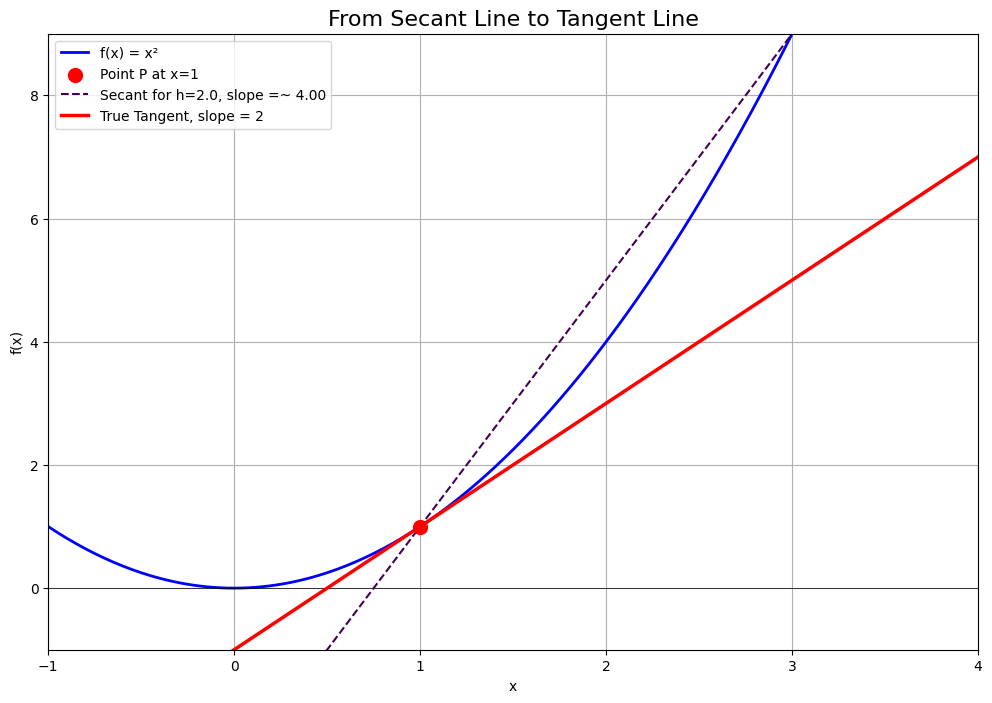

In [10]:

fig, ax = plt.subplots(figsize=(12, 8))
ax.plot(x_range, y_range, label="f(x) = x²", color='blue', linewidth=2)
ax.set_title("From Secant Line to Tangent Line", fontsize=16)
ax.grid(True)
ax.axhline(0, color='black', linewidth=0.5)
ax.axvline(80, color='black', linewidth=0.5)

# Plot the point P where we are finding the slope
P = (x_point, f(x_point))
ax.scatter(*P, color='red', s=100, zorder=5, label=f"Point P at x={x_point}")

# Loop through our h_values to draw the secant lines
for i, h in enumerate(h_values):
    # Calculate the second point, Q
    Q = (x_point + h, f(x_point + h))

    # Calculate the slope of the secant line
    secant_slope = (Q[1] - P[1]) / (Q[0] - P[0])

    # Define the secant line function
    secant_line = lambda x: secant_slope * (x - P[0]) + P[1]

    # Plot the secant line
    line_color = plt.cm.viridis(i / len(h_values)) # gets a color gradient
    ax.plot(x_range, secant_line(x_range), linestyle='--', color=line_color,
        label=f"Secant for h={h}, slope =~ {secant_slope:.2f}")

    # The true tangent line (we know the derivative of x² is 2x, so at x=1, the slope is 2)
    tangent_slope = 2 * x_point
    tangent_line = lambda x: tangent_slope * (x - P[0]) + P[1]
    ax.plot(x_range, tangent_line(x_range), color='red', linewidth=2.5,
        label=f"True Tangent, slope = {tangent_slope}")

    ax.set_xlabel("x")
    ax.set_ylabel("f(x)")
    ax.set_ylim(-1, 9)
    ax.set_xlim(-1, 4)
    ax.legend()
    plt.show()

## 2.: Calculating the Derivative
The process just visualized is formalized by the **limit definition of the derivative**:
$$
f'(x)=\lim_{h\to0}\frac{f(x+h)-f(x)}{h})
$$
The notation $f'(x)$ (read "f prime of x") is one the common ways to write the derivate of $f(x)$

Let's turn this into a python function to compute the derivative numerically. We cant make $h$ truly zero, as that would cause a division by zero error, but we can make it a very small number, like $1\cdot10^{-7} \,\, (1\text{e}-7)$

The derivative of f(x)=x² at x=1 is approximately: 2.0000001010878066
The derivate of f(x)=x² at x=3 is approximately: 6.000000087880153
The derivative of g(x)=x³+2x at x=2 is approximately: 14.000000589931005
At x=1.0, the point is (1.00, 1.0) and the slope is 2.00
At x=3.0, the point is (3.00, 9.0) and the slope is 6.00
At x=2.0, the point is (2.00, 1.2e+01) and the slope is 14.00


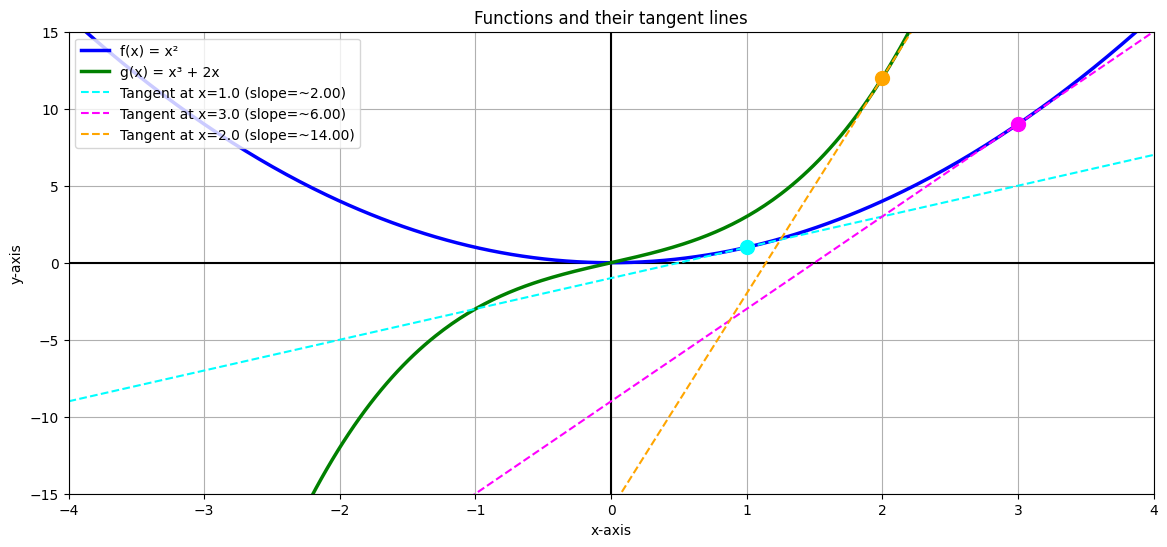

In [18]:
# 1. Our function f(x) = x²
def f1(x):
    return x**2

# 2. A more complex function g(x) = x³ + 2x
def f2(x):
    return x**3 + 2*x

def numerical_derivative(func, x, h=1e-7):
    """
    Calculates the numerical derivative of a function 'func' at point 'x'.

    Args:
        func (function): The function to differentiate
        x (float): The point at which to find the derivative
        h (float): A very small number to approximate the limit.

    Returns:
        The approximate slope of the tangent line at x.
    """
    return (func(x + h) - func(x)) / h

def plot_tangent(func, x_point, color='red'):
    """
    A helper function to calculate and plot the tangent line for a function at a given point.
    """
    # 1. Find the y-value at the point of tangency
    y_point = func(x_point)

    # 2. Calculate the slope (derivative) at that point)
    slope = numerical_derivative(func, x_point)
    print(f"At x={x_point}, the point is ({x_point:.2f}, {y_point:.2}) and the slope is {slope:.2f}")

    # 3. Define the tangent line using point-slope form: y = m(x - x1) + y1
    tangent_line = lambda x: slope * (x - x_point) + y_point

    # 4. Plot the point of tangency and the tangent line
    plt.scatter(x_point, y_point, color=color, s=100, zorder=5) # zorder=5 makes the dot appear on top
    plt.plot(x_values, tangent_line(x_values), color=color, linestyle='--',
             label=f"Tangent at x={x_point} (slope=~{slope:.2f})")

# Let's test it:

# Calculate derivative of f1(x) at x=1
deriv_at_1 = numerical_derivative(f1, 1)
print(f"The derivative of f(x)=x² at x=1 is approximately: {deriv_at_1}")

# Calculate derivate of f1(x) at x=3
deriv_at_3 = numerical_derivative(f1, 3)
print(f"The derivate of f(x)=x² at x=3 is approximately: {deriv_at_3}")

# Calculate derivate of f2(x) at x=2
deriv_f2_at_2 = numerical_derivative(f2, 2)
print(f"The derivative of g(x)=x³+2x at x=2 is approximately: {deriv_f2_at_2}")

# Define our plot
plt.figure(figsize=(14, 6))
plt.grid(True)
plt.axhline(0, color='black', linewidth=1.5) # x-achse
plt.axvline(0, color='black', linewidth=1.5) # y-achse
plt.xlabel("x-axis")
plt.ylabel("y-axis")
plt.title("Functions and their tangent lines")

# generate x_values
x_values = np.linspace(-4, 4, 400)

# draw our functions
y1 = f1(x_values)
plt.plot(x_values, y1, label="f(x) = x²", color='blue', linewidth=2.5)

y2 = f2(x_values)
plt.plot(x_values, y2, label="g(x) = x³ + 2x", color='green', linewidth=2.5)

# --- Add the tanget lines

# For f(x) = x²
plot_tangent(f1, x_point=1.0, color='cyan')
plot_tangent(f1, x_point=3.0, color='magenta') # another one

# For g(x) = x³ + 2x
plot_tangent(f2, x_point=2.0, color='orange')

plt.xlim(-4, 4)
plt.ylim(-15, 15)

plt.legend(loc="upper left")
plt.show()

## Part 3: Finding the Exact Derivative with SymPy

Our `numerical_derivative` function is great for building intuition, but it's an approximation. For exact answers, we need symbolic mathematics. This is where the `sympy` library shines. It treats variables as symbols, not as numbers with a specific value.

Let's use SymPy to find the derivative of `f(x) = x²`. We'll tell it what our variable is, define the function, and then ask it to differentiate.

In [2]:
import sympy as sp

# 1. Declare 'x' as a mathematical symbol
x = sp.Symbol('x')

# 2. Define our function symbolically
f_symbolic = x**2

# 3. Use sympy.diff() to find the derivative with respect to x
f_prime = sp.diff(f_symbolic, x)

print(f"The function is: f(x) = {f_symbolic}")
print(f"The derivative is: f'(x) = {f_prime}")

The function is: f(x) = x**2
The derivative is: f'(x) = 2*x


## Part 4: The Power Rule
What we just saw is an example of the **Power Rule**. It's a simple, elegant rule for finding the derivative of functions of the form $x^n$. 

The rule states:
**If $f(x) = x^n$, then its derivative $f'(x) = n \cdot x^{n-1}$**

In simple temrs: "Bring the exponent down in front, then subtract one from the original exponent"

Examples:
- If $f(x) = x^2$, then $n=2$. The derivative is $2 \cdot x^{2-1} = 2x^1 = 2x$
- If $f(x) = x^3$, then $n=3$. The derivative is $3 \cdot x^{3-1} = 3x^2$.
- If $f(x) = x$ (which is $x^1$), then $n=1$. The derivative is $1 \cdot x^{1-1} = 1 \cdot x^0 = 1$.
    Intuitively: the slope of the line $y=x$ is always 1.

The Power Rule also works for constants and other types of exponents, and it combines with constants:
- **Derivative of a constant:** If $f(x) = c$ (like $f(x) = 5$), it's a horizontal line with zero slope. So $f'(x) = 0$.
- **Constant multiple:** The derivative of $c \cdot f(x)$ is $c \cdot f'(x)$. So, the derivative of $7x^2$ is $7 \cdot (2x) = 14x$.
- **Sums and Differences:** The derivative of $f(x) + g(x)$ is $f'(x) + g'(x)$. You can differentiate term by term.

With these rules, any polynomial can now be differentiated!
For $g(x) = x^3 + 2x$:
- The derivative of $x^3$ is $3x^2$
- The derivative of $2x$ is $2$
- So, $g'(x) = 3x^2 + 2$.

Let's verify our numerical calculation for $g(x)$ at $x=2$:
- The exact slope should be $3*(2)² + 2 = 3*4 + 2 = 14$. 
- Our numerical function gave us a result very close to 14.

## Part 5: The Chain Rule
The Power Rule is great, but only works for simple functions ($x^n$). What if we have **composite functions**, something like $f(x) = (x^2 + 1)^3$ or $h(x) = sin(x^2)$? 

This is where the **Chain Rule** comes in. 
Let's say we have a function $y = f(g(x))$
- $f$ is the "outer" function
- $g$ is the "innter" function

The Chain Rule states:
**$y = f'(g(x)) * g'(x)$**

In words: **"Take the derivative of the outer function (leaving the inner function as is), then multiply by the derivative of the inner function."**

Let's break it down (🕺) for $y = (x^2 +1)^3$:
1. **Identify functions:**
   - Outer function : $f(u) = u^3$ (where $u$ is the "inside stuff")
   - Inner function: $g(x) = x^1 + 1$
2. **Find their derivates:**
   - $f'(u) = 3u²$ (using the Power Rule)
   - $g'(x) = 2x$ (using the Power Rule)
3. **Apply the Chain Rule $f'(g(x)) * g'(x)$:
   - $f(g(x))$ means take the derivative of the outer function, $3u^2$, and plug the *original* inner function back in for $u$. So it becomes $3(x^2 + 1)^2$.
   - Multply by the derivate of the inner function, $g'(x)$, which is $2x$.
4. **Combine:**
   - $y' = 3(x^2 + 1)^2 \cdot 2x = 6x(x^2 + 1)^2$

Let's see if SymPy agrees with our manual Chain Rule calculation:

In [3]:
import sympy as sp

# Declare the symbol again for clarity
x = sp.Symbol('x')

# -- Exmaple 1: Above ---
h_symbolic = (x**2 + 1)**3
h_prime = sp.diff(h_symbolic, x)

print(f"The function is: h(x) = {h_symbolic}")
print(f"The derivative is: h'(x) = {h_prime}")

print(f"Factored form: {sp.factor(h_prime)}")
print("-" * 30)

# --- Example 2: A trigonomic one
# Take sin(x²)
# Outer function: sin(u) -> derivative is cos(u)
# Inner function: x²     -> derivative is 2x
# Expected result: cos(x²) * 2x

k_symbolic = sp.sin(x**2)
k_prime = sp.diff(k_symbolic, x)

print(f"The function is: k(x) = {k_symbolic}")
print(f"The derivative is: k'(x) = {k_prime}")

The function is: h(x) = (x**2 + 1)**3
The derivative is: h'(x) = 6*x*(x**2 + 1)**2
Factored form: 6*x*(x**2 + 1)**2
------------------------------
The function is: k(x) = sin(x**2)
The derivative is: k'(x) = 2*x*cos(x**2)


## Part 6: A Visual Intuition for the Chain Rule
Let's visualize the Chain Rule with the function $h(x) = sin(x^2)$. We want to understand why the slope of $h(x)$ is the product of the slopes of its parts.

Below are three panels to see how a change in $x$ propagates through the two functions:
1. **Panel 1 (Top Left):** The inner function, $g(x) = x^2)$. We'll see its slope at a specific point $x$. This tells us how fast the input to the next stage is changing.
2. **Panel 2 (Top Right):** The outer function, $f(u) = sin(u)$. We'll see its slope at the point $u$ that was the *output from Panel 1. This tells us how much the outer function "amplifies" or "dampens" the change it receives.
3. **Panel 3 (Bottom):** The final composite function, $h(x) = sin(x^2)$. Its slope should be the product of the two slopes above.

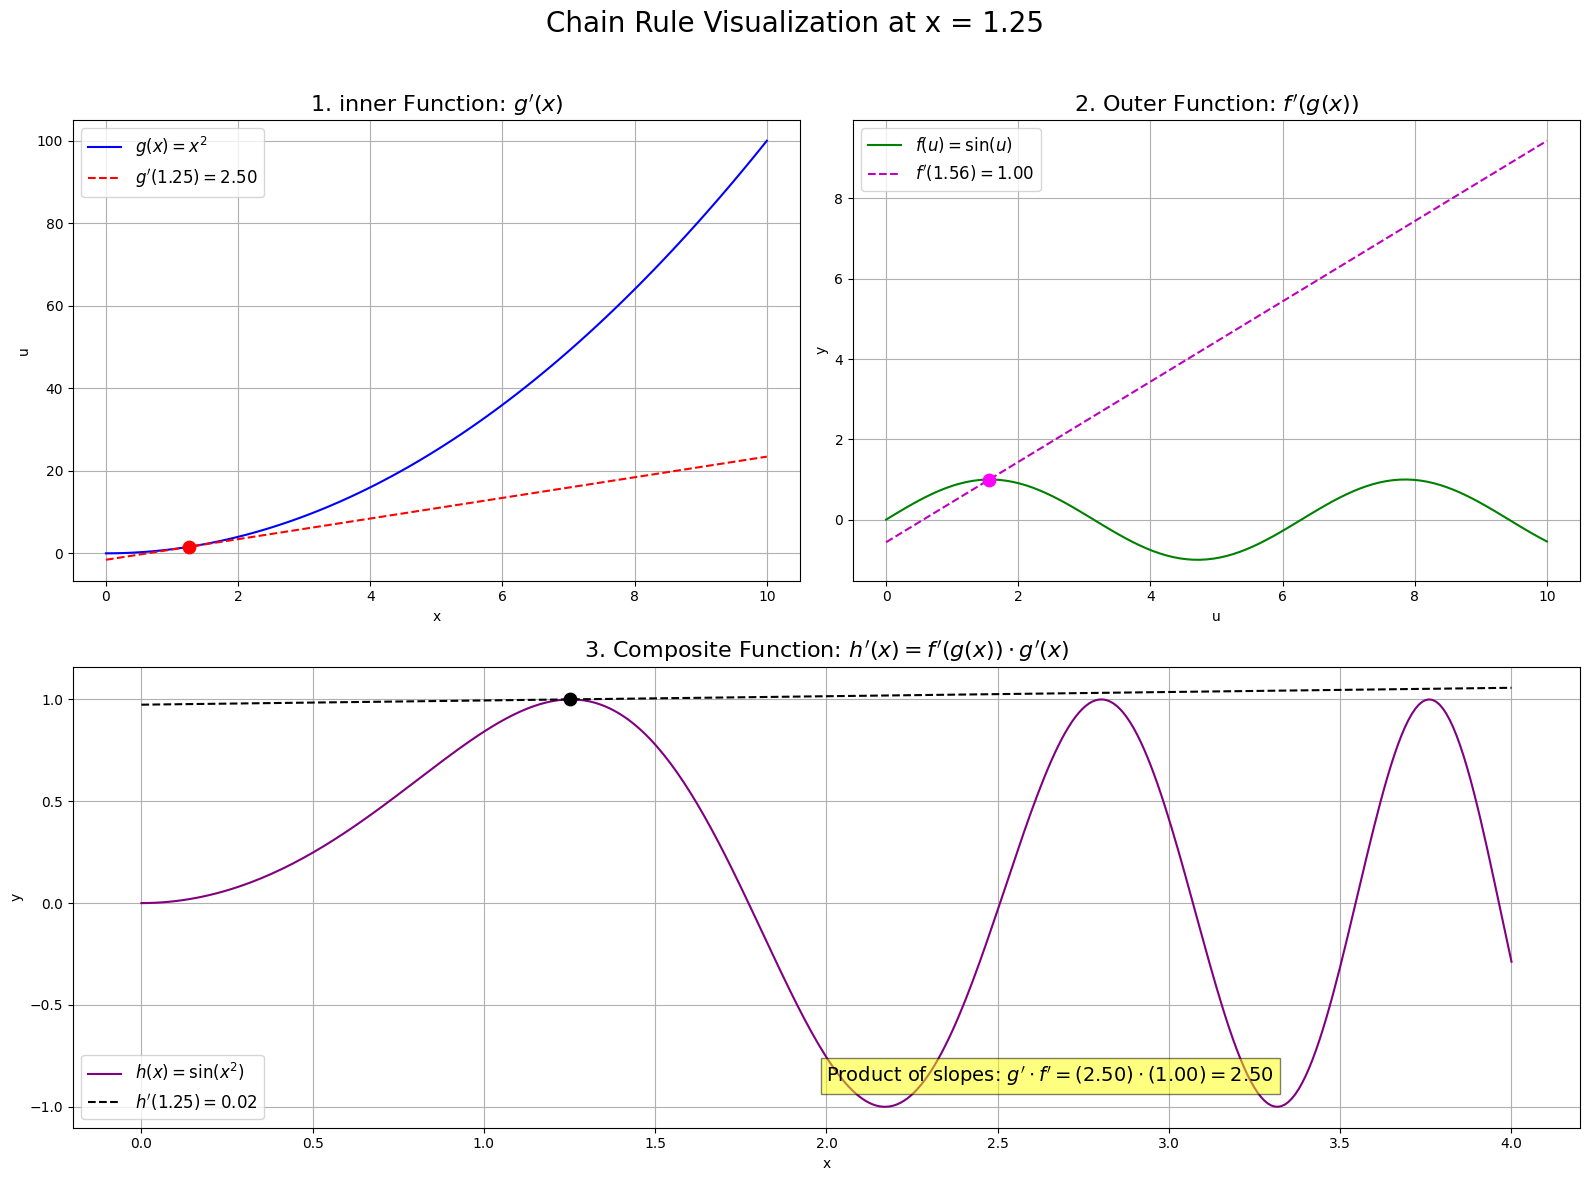

In [35]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp

# --- Define functions symbolically with SymPy to get exact derivatives
x_sym, u_sym = sp.symbols('x u')

# Inner function g(x) = x²
g_sym = x_sym**2
g_prime_sym = sp.diff(g_sym, x_sym)

# Outer function f(u) = sin(u)
f_sym = sp.sin(u_sym)
f_prime_sym = sp.diff(f_sym, u_sym)

# Composite function h(x) = sin(x²)
h_sym = sp.sin(x_sym**2)
h_prime_sym = sp.diff(h_sym, x_sym)

# --- Convert symbolic functions to numerical functions for plotting
# This is a powerful technique using sympy.lambdify
g = sp.lambdify(x_sym, g_sym, 'numpy')
g_prime = sp.lambdify(x_sym, g_prime_sym, 'numpy')
f = sp.lambdify(u_sym, f_sym, 'numpy')
f_prime = sp.lambdify(u_sym, f_sym, 'numpy')
h = sp.lambdify(x_sym, h_sym, 'numpy')
h_prime = sp.lambdify(x_sym, h_prime_sym, 'numpy')

# --- The Point of Interest ---
x_point = 1.25
u_point = g(x_point) # The output of g becomes the input for f

# --- Create the plot ---
fig = plt.figure(figsize=(16, 12))
fig.suptitle(f"Chain Rule Visualization at x = {x_point}", fontsize=20)

# --- Panel 1: Inner function g(x) = x²
ax1 = plt.subplot(2, 2, 1)
x_vals = np.linspace(0, 10, 100)
ax1.plot(x_vals, g(x_vals), label=r"$g(x) = x^2$", color='blue')
ax1.set_title(r"1. inner Function: $g'(x)$", fontsize=16)
ax1.set_xlabel('x')
ax1.set_ylabel('u')
ax1.grid(True)

# Tangent line for g(x)
slope_g = g_prime(x_point)
tangent_g = slope_g * (x_vals - x_point) + u_point
ax1.plot(x_vals, tangent_g, 'r--', label=f"$g'({x_point:.2f}) = {slope_g:.2f}$")
ax1.scatter(x_point, u_point, color='red', s=80, zorder=5)
ax1.legend(fontsize=12)

# --- Panel 2: Outer function f(u) = sin(u) ---
ax2 = plt.subplot (2, 2, 2)
u_vals = np.linspace(0, 10, 100)
ax2.plot(u_vals, f(u_vals), label=r"$f(u) = \sin(u)$", color='green')
ax2.set_title(r"2. Outer Function: $f'(g(x))$", fontsize=16)
ax2.set_xlabel('u')
ax2.set_ylabel('y')
ax2.grid(True)

# Tangent line for f(u)
slope_f = f_prime(u_point)
tangent_f = slope_f * (u_vals - u_point) + f(u_point)
ax2.plot(u_vals, tangent_f, 'm--', label=f"$f'({u_point:.2f}) = {slope_f:.2f}$")
ax2.scatter(u_point, f(u_point), color='magenta', s=80, zorder=5)
ax2.legend(fontsize=12)

# --- Panel 3: Composite function f(x) = sin(x²) ---
ax3 = plt.subplot(2, 1, 2)
x_vals_h = np.linspace(0, 4, 400)
ax3.plot(x_vals_h, h(x_vals_h), label=r"$h(x) = \sin(x^2)$", color='purple')
ax3.set_title(r"3. Composite Function: $h'(x) = f'(g(x)) \cdot g'(x)$", fontsize=16)
ax3.set_xlabel('x')
ax3.set_ylabel('y')
ax3.grid(True)

# Tangent line for h(x)
slope_h = h_prime(x_point)
tangent_h = slope_h * (x_vals_h - x_point) + h(x_point)
ax3.plot(x_vals_h, tangent_h, 'k--', label=f"$h'({x_point:.2f}) = {slope_h:.2f}$")
ax3.scatter(x_point, h(x_point), color='black', s=80, zorder=5)
ax3.legend(fontsize=12)

# --- Final verification text ---
product_of_slopes = slope_g * slope_f
ax3.text(0.5, 0.1,
         f"Product of slopes: $g' \cdot f' = ({slope_g:.2f}) \cdot ({slope_f:.2f}) = {product_of_slopes:.2f}$",
         transform=ax3.transAxes, fontsize=14, bbox=dict(facecolor='yellow', alpha=0.5))

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()



## Next Steps
So far, we've looked at functions like $y = f(x)$. They have one input ($x$) and one output ($y$), which we can draw on a 2D plane. The derivative $f'(x)$ gives us the slope of the curve at a point.

In some situations, the function doesn't just depend on one thing though
.... Insert transition to next